# Made by Dominic Hildebrand with cooperation from Meint Eybergen
Analyse the kaiju results.
May, 2025

Aug update: This file works 'good enough' and could be made better, but wasn't.
Sorry to any people that want to continue working on this, hope it is clear 
enough to work with...

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from matplotlib import colormaps
import matplotlib.colors as mcolors


In [3]:
# Do not forget to change append to 'species' if you want to allow genus level... Yeah it's weird. 

df = pd.read_csv("C:/Users/domin/Downloads/kaiju_summary_complete_species.tsv", sep="\t")
# df = pd.read_csv("C:/Users/domin/Downloads/kaiju_summary_complete_genus.tsv", sep="\t")
# "C:\Users\domin\Downloads\all_samples_summary_genus.tsv"
# df = pd.read_csv("/lustre/BIF/nobackup/hilde017/kaiju/liberibacter_metagenomics/results/summary_kaiju/kaiju_summary_complete_species.tsv", sep="\t")


# IMPORTANT!!! 
# When using summary complete species, make 'append' species.
# When using summary complete genus, make 'append' genus. 
# This variable determines which classification level to use.
# IMPORTANT!!!

append = "species"
# append = "genus"

df.fillna("unclassified", inplace=True)
df

C:\Users\domin\AppData\Local\Temp\ipykernel_6420\1298050876.py:3: DtypeWarning: Columns (0) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("C:/Users/domin/Downloads/kaiju_summary_complete_species.tsv", sep="\t")


,taxon_id,4-04a--on--14-10,6-06a--2-5--06-10,3-wgt01--5b--08-11,1-01a--press2--13-10,15-07a--2-5--05-10,10-wgt07-775-5--09-10,7-02a--6-0--15-10,1-05b--sed--29-10,6-wgt04--3---75,...,1-01a--press1--13-10,4-04c--6-0--17-10,10-01b--11--28-10,2-wgt04--b4su--17-10,phylum,class,order,family,genus,species
0,29833,936970,6666,9961489,2875763,309636,89648,204401,510891,780403,...,1906914,47749,563763,2686215,Ascomycota,Saccharomycetes,Saccharomycetales,Saccharomycodaceae,Hanseniaspora,Hanseniaspora uvarum
1,4932,337188,1481703,3061687,26676,1475813,1054176,2840494,13166,4498725,...,17073,1086136,5683628,2457,Ascomycota,Saccharomycetes,Saccharomycetales,Saccharomycetaceae,Saccharomyces,Saccharomyces cerevisiae
2,5580,112351,242888,23099,4389677,119640,30833,51992,3065925,329252,...,9995195,68383,65067,97006,Ascomycota,Dothideomycetes,Dothideales,Saccotheciaceae,Aureobasidium,Aureobasidium pullulans
3,329,105715,24232,92199,111728,19236,1871,23062,320096,280568,...,131712,14102,25095,127911,Pseudomonadota,Betaproteobacteria,Burkholderiales,Burkholderiaceae,Ralstonia,Ralstonia pickettii
4,2502223,50657,22801,73424,87295,25125,2013,19686,270713,220220,...,85682,11773,31064,138524,Pseudomonadota,Betaproteobacteria,Burkholderiales,Burkholderiaceae,Burkholderia,Burkholderia sp. 4M9327F10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
57956,2508342,0,0,0,0,0,0,0,0,0,...,0,0,0,1,Cyanobacteriota,Cyanophyceae,Synechococcales,Synechococcaceae,Synechococcus,Synechococcus sp. PH41509
57957,2509793,0,0,0,0,0,0,0,0,0,...,0,0,0,1,Basidiomycota,Agaricomycetes,Auriculariales,Hyaloriaceae,Protomerulius,Protomerulius madidus
57958,2597350,0,0,0,0,0,0,0,0,0,...,0,0,0,1,Pseudomonadota,Gammaproteobacteria,Pseudomonadales,Pseudomonadaceae,Pseudomonas,Pseudomonas sp. ANT_H4
57959,2604835,0,0,0,0,0,0,0,0,0,...,0,0,0,1,Bacillota,Bacilli,Bacillales,Bacillaceae,Bacillus,Bacillus sp. Y3


In [4]:
def rearrange_string(input_string):
    """Rename string based on the first and second and rest, split on '-'.
    Returns same string if cannot re-arrange string. 
    Example: renames '4-04a--on--14-10' to '04a-4--on--14-10'.

    Args:
        input_string (str): String

    Returns:
        str: refactored string
    """    
    # Split the string into two parts at the first occurrence of '-'
    try:
        first_part, rest = input_string.split('-', 1)

        # Split the rest of the string into two parts at the first occurrence of '-'
        second_part, third_part = rest.split('-', 1)

        # Rearrange the parts, zfill gives us 01 instead of just 1, easier sort
        rearranged_string = f"{second_part}-{first_part.zfill(2)}-{third_part}"
    except ValueError:
        rearranged_string = input_string
    return rearranged_string


In [5]:
rename_columns = True
if rename_columns:
    changelist = list(df.columns)
    changedlist = []
    # [rearrange_string(file) for file in changelist]
    for file in changelist:
        changedlist.append(rearrange_string(file))
    df.columns = changedlist
# df

In [6]:
df

,taxon_id,04a-04--on--14-10,06a-06--2-5--06-10,wgt01-03--5b--08-11,01a-01--press2--13-10,07a-15--2-5--05-10,wgt07-10-775-5--09-10,02a-07--6-0--15-10,05b-01--sed--29-10,wgt04-06--3---75,...,01a-01--press1--13-10,04c-04--6-0--17-10,01b-10--11--28-10,wgt04-02--b4su--17-10,phylum,class,order,family,genus,species
0,29833,936970,6666,9961489,2875763,309636,89648,204401,510891,780403,...,1906914,47749,563763,2686215,Ascomycota,Saccharomycetes,Saccharomycetales,Saccharomycodaceae,Hanseniaspora,Hanseniaspora uvarum
1,4932,337188,1481703,3061687,26676,1475813,1054176,2840494,13166,4498725,...,17073,1086136,5683628,2457,Ascomycota,Saccharomycetes,Saccharomycetales,Saccharomycetaceae,Saccharomyces,Saccharomyces cerevisiae
2,5580,112351,242888,23099,4389677,119640,30833,51992,3065925,329252,...,9995195,68383,65067,97006,Ascomycota,Dothideomycetes,Dothideales,Saccotheciaceae,Aureobasidium,Aureobasidium pullulans
3,329,105715,24232,92199,111728,19236,1871,23062,320096,280568,...,131712,14102,25095,127911,Pseudomonadota,Betaproteobacteria,Burkholderiales,Burkholderiaceae,Ralstonia,Ralstonia pickettii
4,2502223,50657,22801,73424,87295,25125,2013,19686,270713,220220,...,85682,11773,31064,138524,Pseudomonadota,Betaproteobacteria,Burkholderiales,Burkholderiaceae,Burkholderia,Burkholderia sp. 4M9327F10
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
57956,2508342,0,0,0,0,0,0,0,0,0,...,0,0,0,1,Cyanobacteriota,Cyanophyceae,Synechococcales,Synechococcaceae,Synechococcus,Synechococcus sp. PH41509
57957,2509793,0,0,0,0,0,0,0,0,0,...,0,0,0,1,Basidiomycota,Agaricomycetes,Auriculariales,Hyaloriaceae,Protomerulius,Protomerulius madidus
57958,2597350,0,0,0,0,0,0,0,0,0,...,0,0,0,1,Pseudomonadota,Gammaproteobacteria,Pseudomonadales,Pseudomonadaceae,Pseudomonas,Pseudomonas sp. ANT_H4
57959,2604835,0,0,0,0,0,0,0,0,0,...,0,0,0,1,Bacillota,Bacilli,Bacillales,Bacillaceae,Bacillus,Bacillus sp. Y3


In [7]:
columns = df.select_dtypes(include=np.number).columns.tolist()


columns.append(append)
# columns.append("phylum")

df_test = df[columns]

In [8]:
# aggregate_df = df_test.groupby("phylum").sum()
df_test.rename(columns={append : "phylum"}, inplace=True)

aggregate_df = df_test.groupby("phylum").sum()
aggregate_df = aggregate_df.reindex(sorted(aggregate_df.columns), axis=1)
# aggregate_df

C:\Users\domin\AppData\Local\Temp\ipykernel_6420\653589474.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_test.rename(columns={append : "phylum"}, inplace=True)


# WARNING!!! HERE WE CAN FILTER OUT UNCLASSIFIED !!!

In [9]:
# Make a copy of the DataFrame to store relative abundances
df_relative = aggregate_df.copy()

# HASH OUT IF YOU WANT TO SEE UNCLASSIFIED
df_relative = df_relative[~df_relative.index.str.contains('unclassified', na=False)]

# Normalize each column (excluding 'phylum') to sum to 100%
for col in df_relative.columns[0:]:  # Skip the 'phylum' column
    df_relative[col] = (df_relative[col] / df_relative[col].sum()) * 100

# df_relative
filterlist = df_relative

In [10]:
# filterlist
# filterlist.to_csv("filterlist_species.tsv", sep="\t")

In [11]:
for value in filterlist.columns:
    print(value)

01a-01--press1--13-10
01a-01--press2--13-10
01a-04--sed--14-10
01a-05--on--19-10
01a-06--2-5--20-10
01a-07--4-0--21-10
01a-08--6-0--23-10
01a-09--8--24-10
01a-10--11--28-10
01a-11--rack--02-11
01b-02--press1--13-10
01b-02--press2--13-10
01b-04--sed--14-10
01b-05--on--19-10
01b-06--2-5--20-10
01b-07--4-0--21-10
01b-08--6-0--23-10
01b-09--8--24-10
01b-10--11--28-10
01b-11--rack--02-11
01c-01--on--19-10
01c-02--2-5--20-10
01c-03--4-0--21-10
01c-03--press1--13-10
01c-03--press2--13-10
01c-04--6-0--23-10
01c-05--8--24-10
01c-06--11--28-10
01c-07--rack--02-11
02a-01--press--07-10
02a-03--sed--08-10
02a-04--on--11-10
02a-05--2-5--13-10
02a-06--4-0--14-10
02a-07--6-0--15-10
02a-08--8--17-10
02a-09--11--20-10
02a-10--rack--24-10
02b-01--sed--08-10
02b-02--on--11-10
02b-02--press--07-10
02b-03--2-5--13-10
02b-04--4-0--14-10
02b-05--6-0--15-10
02b-06--8--17-10
02b-07--11--20-10
02b-08--rack--24-10
02c-01--on--11-10
02c-02--2-5--13-10
02c-03--4-0--14-10
02c-04--6-0--15-10
02c-05--8--17-10
02c-06--

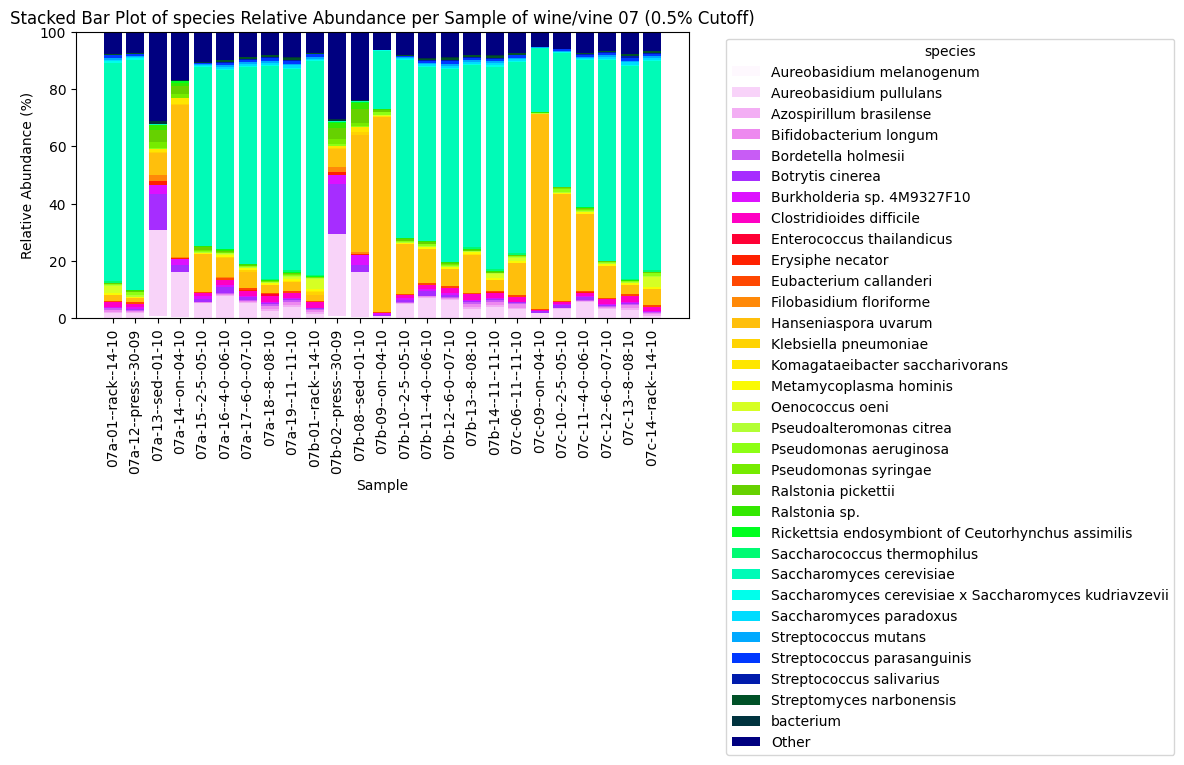

In [14]:
# This variable allows us to list what kind of groups we want to make, REGEX form
locations = [
            # "^01a|^wgt01|^15|^17|^18",
            #  "^01b",
            #  "^01c",
            #  "02",
            #  "03",
            #  "04",
            #  "05",
            #  "06",
             "^07",
            #  "^01a|^15|^17|^18|^wgt01"
            #  "^\d{0,2}a",
            #  "^\d{0,2}b",
            #  "^\d{0,2}c",
            #  "^wgt0*",
            #  ".*--press.*",
            #  ".*--sed.*",
            #  ".*--on.*",
            #  ".*--2.5.*",
            #  ".*--4.*",
            #  ".*--8.*",
            #  ".*--11.*",
            #  ".*--rack.*",
            ]

cutoff = 0.5

# I agree, this should've been a function ._.
# This was real messy to make though... But it works. Makes neat figures.
for location in locations:

    df_relative = filterlist.filter(regex="^.{0,3}" + location + ".*")
    # df_relative = df_relative.filter(regex="^.{0,3}01.*")

    # Reset index to bring 'phylum' back as a column
    df_relative_reset = df_relative.reset_index()

    # Identify phyla with all values < cutoff % across all samples
    low_abundance_phyla = df_relative_reset.loc[(df_relative_reset.iloc[:, 1:] < cutoff).all(axis=1), "phylum"]

    # Sum values of low abundance phyla
    low_abundance_sum = df_relative_reset.loc[df_relative_reset["phylum"].isin(low_abundance_phyla)].iloc[:, 1:].sum()

    # Remove low abundance phyla from the dataset
    df_filtered = df_relative_reset[~df_relative_reset["phylum"].isin(low_abundance_phyla)]

    # df_filtered = df_filtered[df_filtered["phylum"] != "unclassified"]

    # Append 'Other' category with summed values
    other_row = pd.DataFrame([["Other"] + list(low_abundance_sum)], columns=df_filtered.columns)
    df_filtered = pd.concat([df_filtered, other_row], ignore_index=True)

    # Convert to numeric array for Matplotlib stacking
    samples = df_filtered.columns[1:]  # Sample columns
    phyla = df_filtered["phylum"]  # Phylum names
    values = df_filtered.iloc[:, 1:].values  # Get numeric values

    # Plot stacked barplot with Matplotlib
    fig, ax = plt.subplots(figsize=(12, 6))

    # Define a colormap
    colors = plt.cm.gist_ncar_r(np.linspace(0, 1, len(phyla)))
    # colors = plt.cm.viridis(np.random.rand(len(phyla)))

    # np.random.seed(42)
    # np.random.shuffle(colors)

    # Stackplot (more accurate stacking)
    bottom = np.zeros(len(samples))  # Initialize bottom position for stacking
    for i, (phylum, color) in enumerate(zip(phyla, colors)):
        ax.bar(samples, values[i], bottom=bottom, label=phylum, color=color)
        bottom += values[i]  # Update bottom for next stack

    # Change location to allow writing file. Just replacing regex things.
    location = location.replace("|", "-").replace("^", "").replace("\d{0,2}", "xx").replace("*", "")

    # Formatting
    plt.ylabel("Relative Abundance (%)")
    plt.xlabel("Sample")
    plt.title(f"Stacked Bar Plot of {append} Relative Abundance per Sample of wine/vine {location} ({str(cutoff)}% Cutoff)")
    plt.legend(title=append, bbox_to_anchor=(1.05, 1), loc="upper left")
    plt.xticks(rotation=90)
    plt.ylim(0, 100)  # Ensure bars add up to 100%

    # Show plot
    plt.tight_layout()
    plt.savefig(f"{location}_winevine_{append}.pdf")
    # plt.savefig(f"{location}_winevine_{append}.svg")
    plt.show()
